In [2]:
# === 1. Imports & Setup ===
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# Load data
df = pd.read_csv("../data/ta-data/NG.L.csv", parse_dates=["Date"])
df.set_index("Date", inplace=True)

=== EMA20 Signals (Last 10 Years) ===
Buy signals:  87
Sell signals: 86


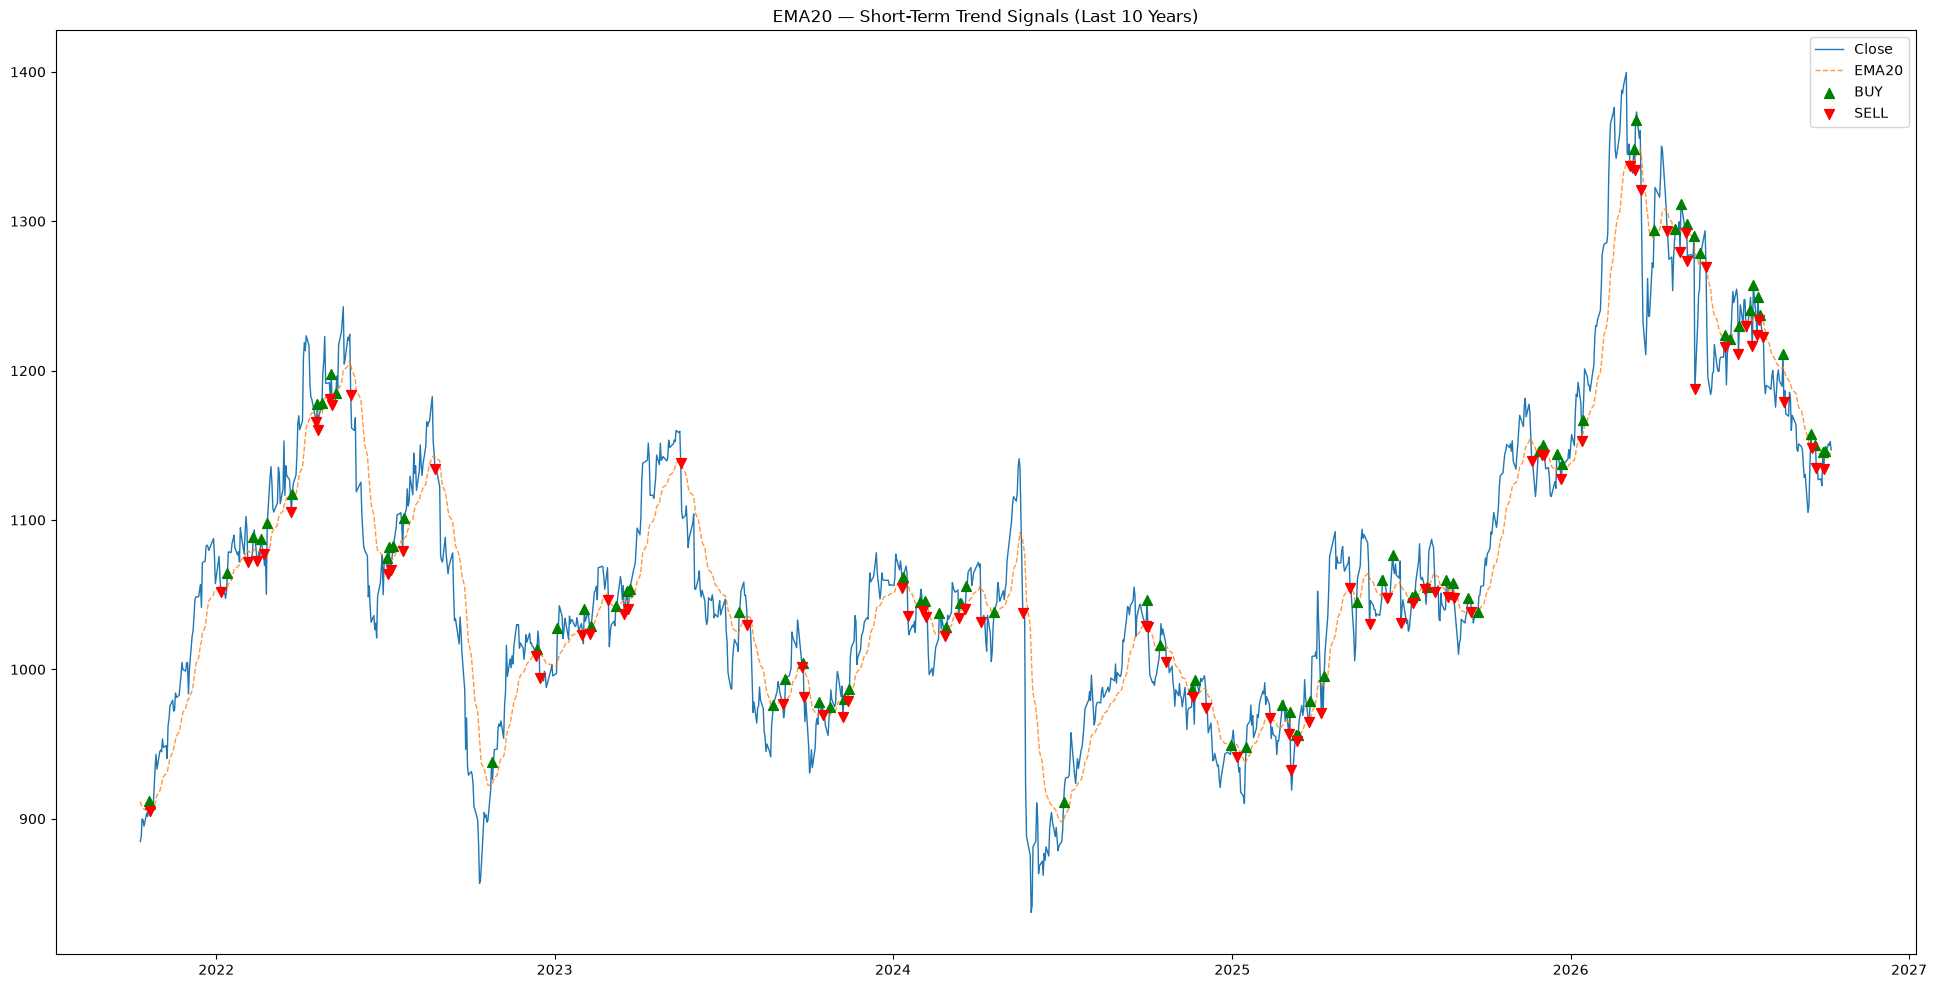

In [16]:
# === 2. EMA20 ===
ema20 = df["ta_ema20"]
close = df["Close"]

# --- FILTER TO LAST 10 YEARS ---
cutoff = df.index.max() - pd.DateOffset(years=5)
df_recent = df[df.index >= cutoff]

close = df_recent["Close"]
ema20 = df_recent["ta_ema20"]

df_recent["price_above_ema20"] = close > ema20
df_recent["prev_above_ema20"] = df_recent["price_above_ema20"].shift(1)
df_recent["ema20_buy_signal"] = (df_recent["price_above_ema20"] == True) & (df_recent["prev_above_ema20"] == False)
df_recent["ema20_sell_signal"] = (df_recent["price_above_ema20"] == False) & (df_recent["prev_above_ema20"] == True)

print("=== EMA20 Signals (Last 10 Years) ===")
print(f"Buy signals:  {df_recent['ema20_buy_signal'].sum()}")
print(f"Sell signals: {df_recent['ema20_sell_signal'].sum()}")

ema20_buy_idx = df_recent[df_recent["ema20_buy_signal"]].index
ema20_buy_prices = close[ema20_buy_idx]
ema20_sell_idx = df_recent[df_recent["ema20_sell_signal"]].index
ema20_sell_prices = close[ema20_sell_idx]

fig, ax = plt.subplots(figsize=(24, 12))
ax.plot(close.index, close, label="Close", linewidth=1)
ax.plot(close.index, ema20, label="EMA20", linestyle="--", linewidth=1, alpha=0.8)
ax.scatter(ema20_buy_idx, ema20_buy_prices, marker="^", color="green", s=50, label="BUY", zorder=5)
ax.scatter(ema20_sell_idx, ema20_sell_prices, marker="v", color="red", s=50, label="SELL", zorder=5)
ax.legend()
ax.set_title("EMA20 — Short-Term Trend Signals (Last 10 Years)")
plt.show()


=== EMA50 Signals (Last 10 Years) ===
Time above EMA50: 57.4%
EMA20 > EMA50:    59.6%


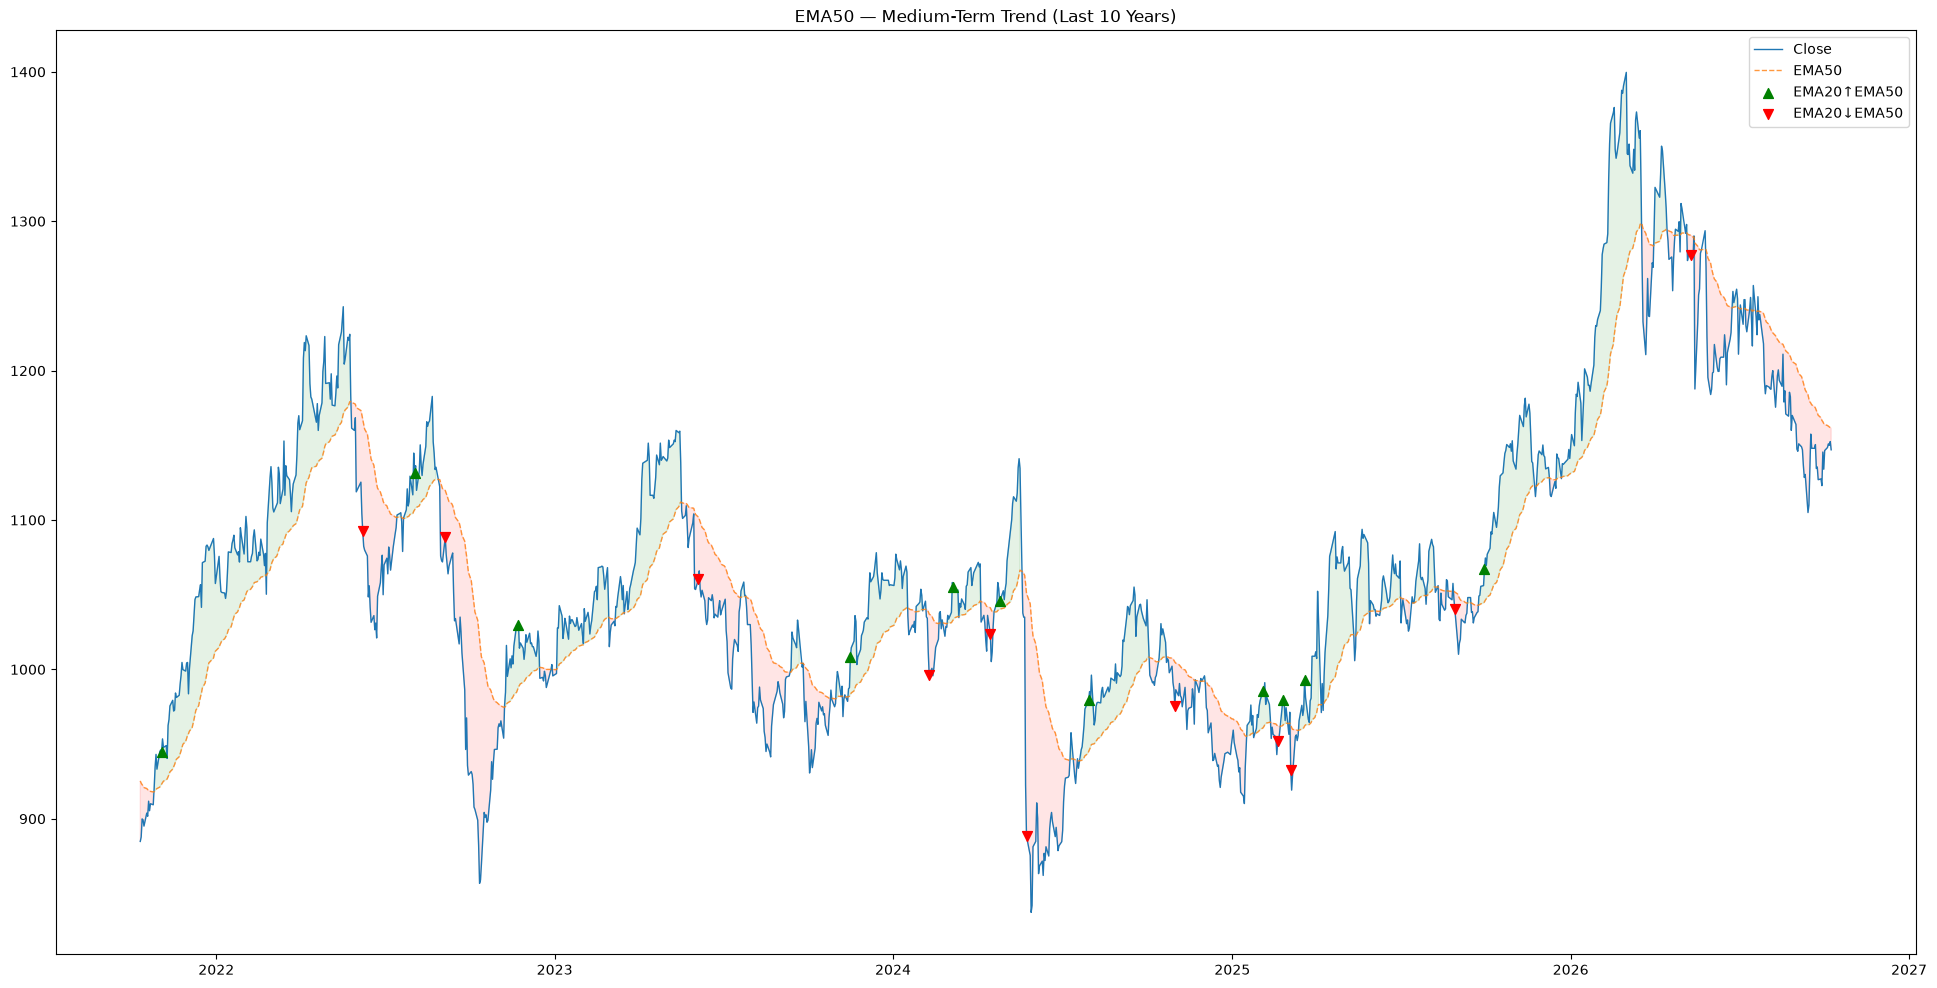

In [18]:
# === 3. EMA50 ===
ema50 = df["ta_ema50"]
close = df["Close"]

# --- FILTER TO LAST 10 YEARS ---
cutoff = df.index.max() - pd.DateOffset(years=5)
df_recent = df[df.index >= cutoff]

close = df_recent["Close"]
ema20 = df_recent["ta_ema20"]
ema50 = df_recent["ta_ema50"]

df_recent["price_above_ema50"] = close > ema50
df_recent["ema20_above_ema50"] = ema20 > ema50
df_recent["prev_ema20_above_ema50"] = df_recent["ema20_above_ema50"].shift(1)
df_recent["ema50_buy_signal"] = df_recent["ema20_above_ema50"] == True
df_recent["ema50_sell_signal"] = df_recent["ema20_above_ema50"] == False
df_recent["golden_cross"] = (df_recent["ema20_above_ema50"] == True) & (df_recent["prev_ema20_above_ema50"] == False)
df_recent["death_cross"] = (df_recent["ema20_above_ema50"] == False) & (df_recent["prev_ema20_above_ema50"] == True)

print("\n=== EMA50 Signals (Last 10 Years) ===")
print(f"Time above EMA50: {(df_recent['price_above_ema50']).mean()*100:.1f}%")
print(f"EMA20 > EMA50:    {(df_recent['ema20_above_ema50']).mean()*100:.1f}%")

ema50_cross_buy_idx = df_recent[df_recent["golden_cross"]].index
ema50_cross_buy_prices = close[ema50_cross_buy_idx]
ema50_cross_sell_idx = df_recent[df_recent["death_cross"]].index
ema50_cross_sell_prices = close[ema50_cross_sell_idx]

fig, ax = plt.subplots(figsize=(24, 12))
ax.plot(close.index, close, label="Close", linewidth=1)
ax.plot(close.index, ema50, label="EMA50", linestyle="--", linewidth=1, alpha=0.8)
ax.fill_between(close.index, close, ema50, where=(close >= ema50), alpha=0.1, color="green")
ax.fill_between(close.index, close, ema50, where=(close < ema50), alpha=0.1, color="red")
ax.scatter(ema50_cross_buy_idx, ema50_cross_buy_prices, marker="^", color="green", s=50, label="EMA20↑EMA50", zorder=5)
ax.scatter(ema50_cross_sell_idx, ema50_cross_sell_prices, marker="v", color="red", s=50, label="EMA20↓EMA50", zorder=5)
ax.legend()
ax.set_title("EMA50 — Medium-Term Trend (Last 10 Years)")
plt.show()


=== EMA200 Long-Term Regime (Last 10 Years) ===
Bull period: 51.0%
Bear period: 49.0%


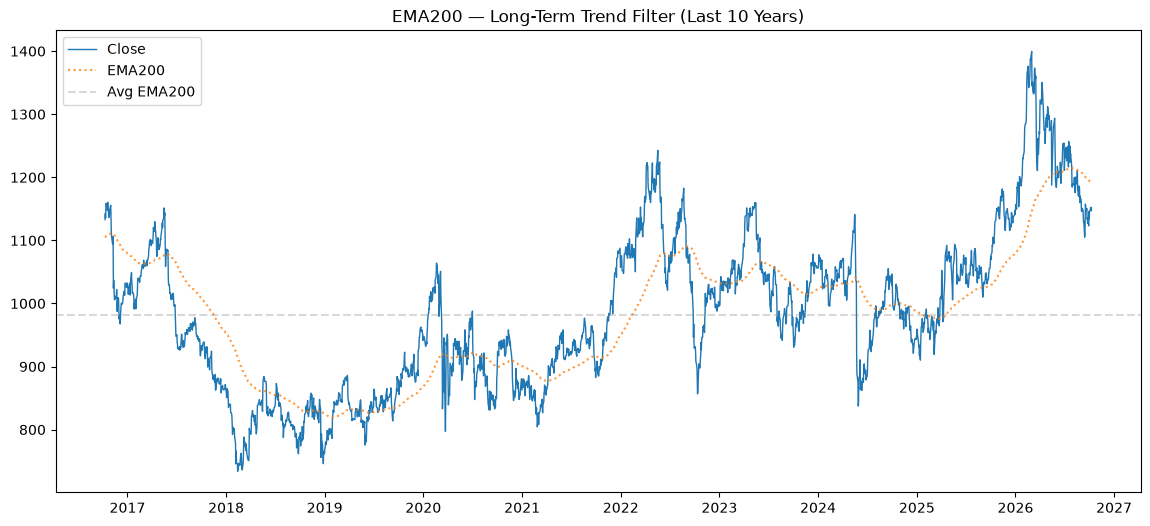

In [19]:
# === 4. EMA200 ===
ema200 = df["ta_ema200"]
close = df["Close"]

# --- FILTER TO LAST 10 YEARS ---
cutoff = df.index.max() - pd.DateOffset(years=10)
df_recent = df[df.index >= cutoff]

close = df_recent["Close"]
ema200 = df_recent["ta_ema200"]

df_recent["price_above_ema200"] = close > ema200
df_recent["regime"] = df_recent["price_above_ema200"].map({True: "BULL", False: "BEAR"})

print("\n=== EMA200 Long-Term Regime (Last 10 Years) ===")
print(f"Bull period: {(df_recent['regime'] == 'BULL').mean()*100:.1f}%")
print(f"Bear period: {(df_recent['regime'] == 'BEAR').mean()*100:.1f}%")

fig, ax = plt.subplots(figsize=(14, 6))
ax.plot(close.index, close, label="Close", linewidth=1)
ax.plot(close.index, ema200, label="EMA200", linestyle=":", linewidth=1.5, alpha=0.8)
ax.axhline(ema200.mean(), color="gray", linestyle="--", alpha=0.3, label="Avg EMA200")
ax.legend()
ax.set_title("EMA200 — Long-Term Trend Filter (Last 10 Years)")
plt.show()


=== Golden Cross / Death Cross (Last 10 Years) ===
Golden Crosses: 10
Death Crosses:  11


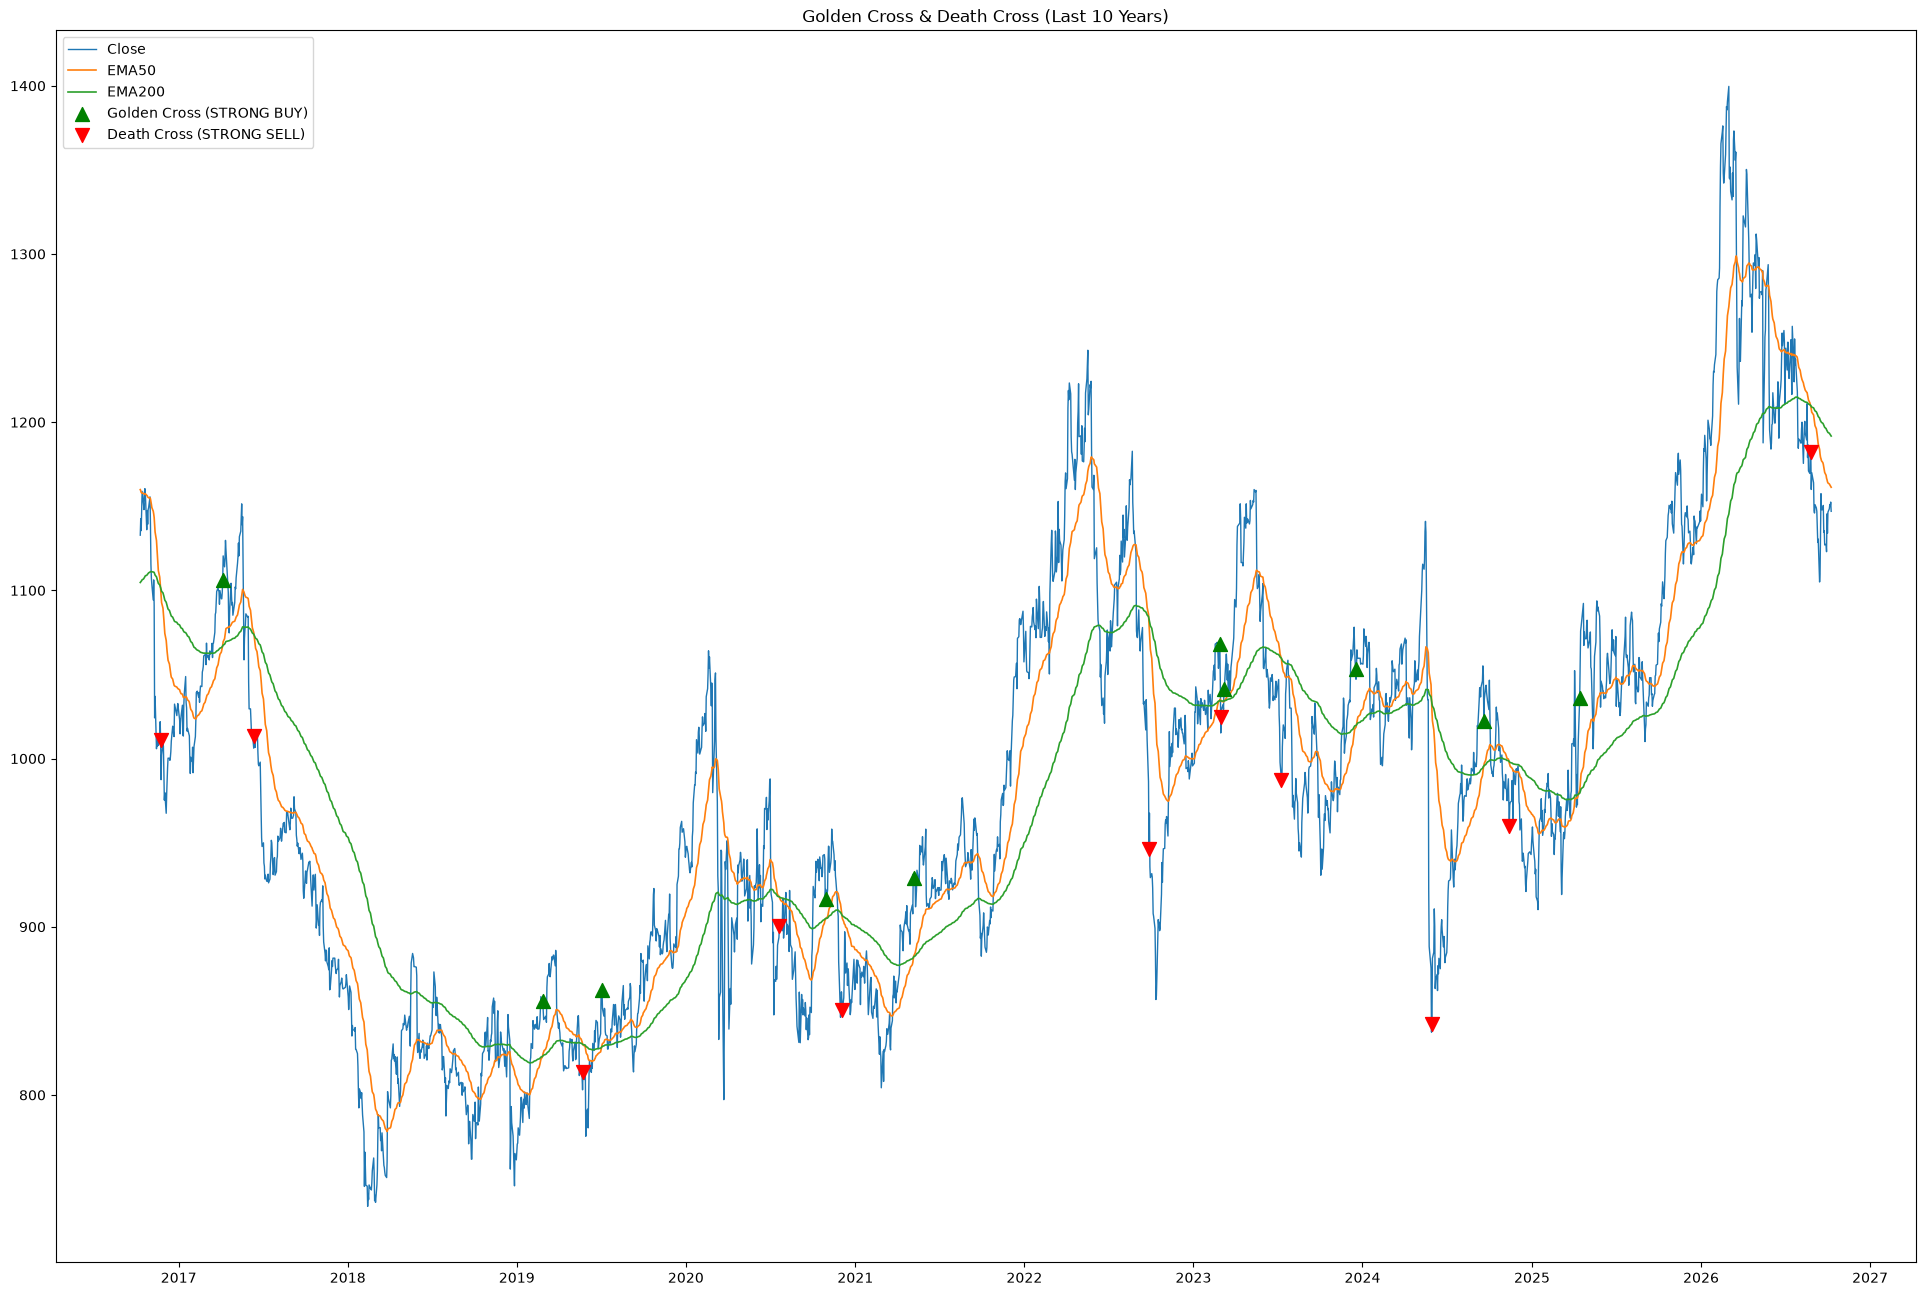

In [21]:
# === 5. Golden Cross & Death Cross ===
# --- FILTER TO LAST 10 YEARS ---
cutoff = df.index.max() - pd.DateOffset(years=10)
df_recent = df[df.index >= cutoff]

close = df_recent["Close"]
ema50 = df_recent["ta_ema50"]
ema200 = df_recent["ta_ema200"]

df_recent["ema50_above_ema200"] = ema50 > ema200
df_recent["prev_ema50_above_ema200"] = df_recent["ema50_above_ema200"].shift(1)
df_recent["golden_cross_strong"] = (df_recent["ema50_above_ema200"] == True) & (df_recent["prev_ema50_above_ema200"] == False)
df_recent["death_cross_strong"] = (df_recent["ema50_above_ema200"] == False) & (df_recent["prev_ema50_above_ema200"] == True)

print("\n=== Golden Cross / Death Cross (Last 10 Years) ===")
print(f"Golden Crosses: {df_recent['golden_cross_strong'].sum()}")
print(f"Death Crosses:  {df_recent['death_cross_strong'].sum()}")

gc_idx = df_recent[df_recent["golden_cross_strong"]].index
gc_prices = close[gc_idx]
dc_idx = df_recent[df_recent["death_cross_strong"]].index
dc_prices = close[dc_idx]

fig, ax = plt.subplots(figsize=(24, 16))
ax.plot(close.index, close, label="Close", linewidth=1)
ax.plot(close.index, ema50, label="EMA50", linewidth=1.2)
ax.plot(close.index, ema200, label="EMA200", linewidth=1.2)
ax.scatter(gc_idx, gc_prices, marker="^", color="green", s=100, zorder=5, label="Golden Cross (STRONG BUY)")
ax.scatter(dc_idx, dc_prices, marker="v", color="red", s=100, zorder=5, label="Death Cross (STRONG SELL)")
ax.legend()
ax.set_title("Golden Cross & Death Cross (Last 10 Years)")
plt.show()


=== SuperTrend Signals (Last 10 Years) ===
Buy signals:  93
Sell signals: 93


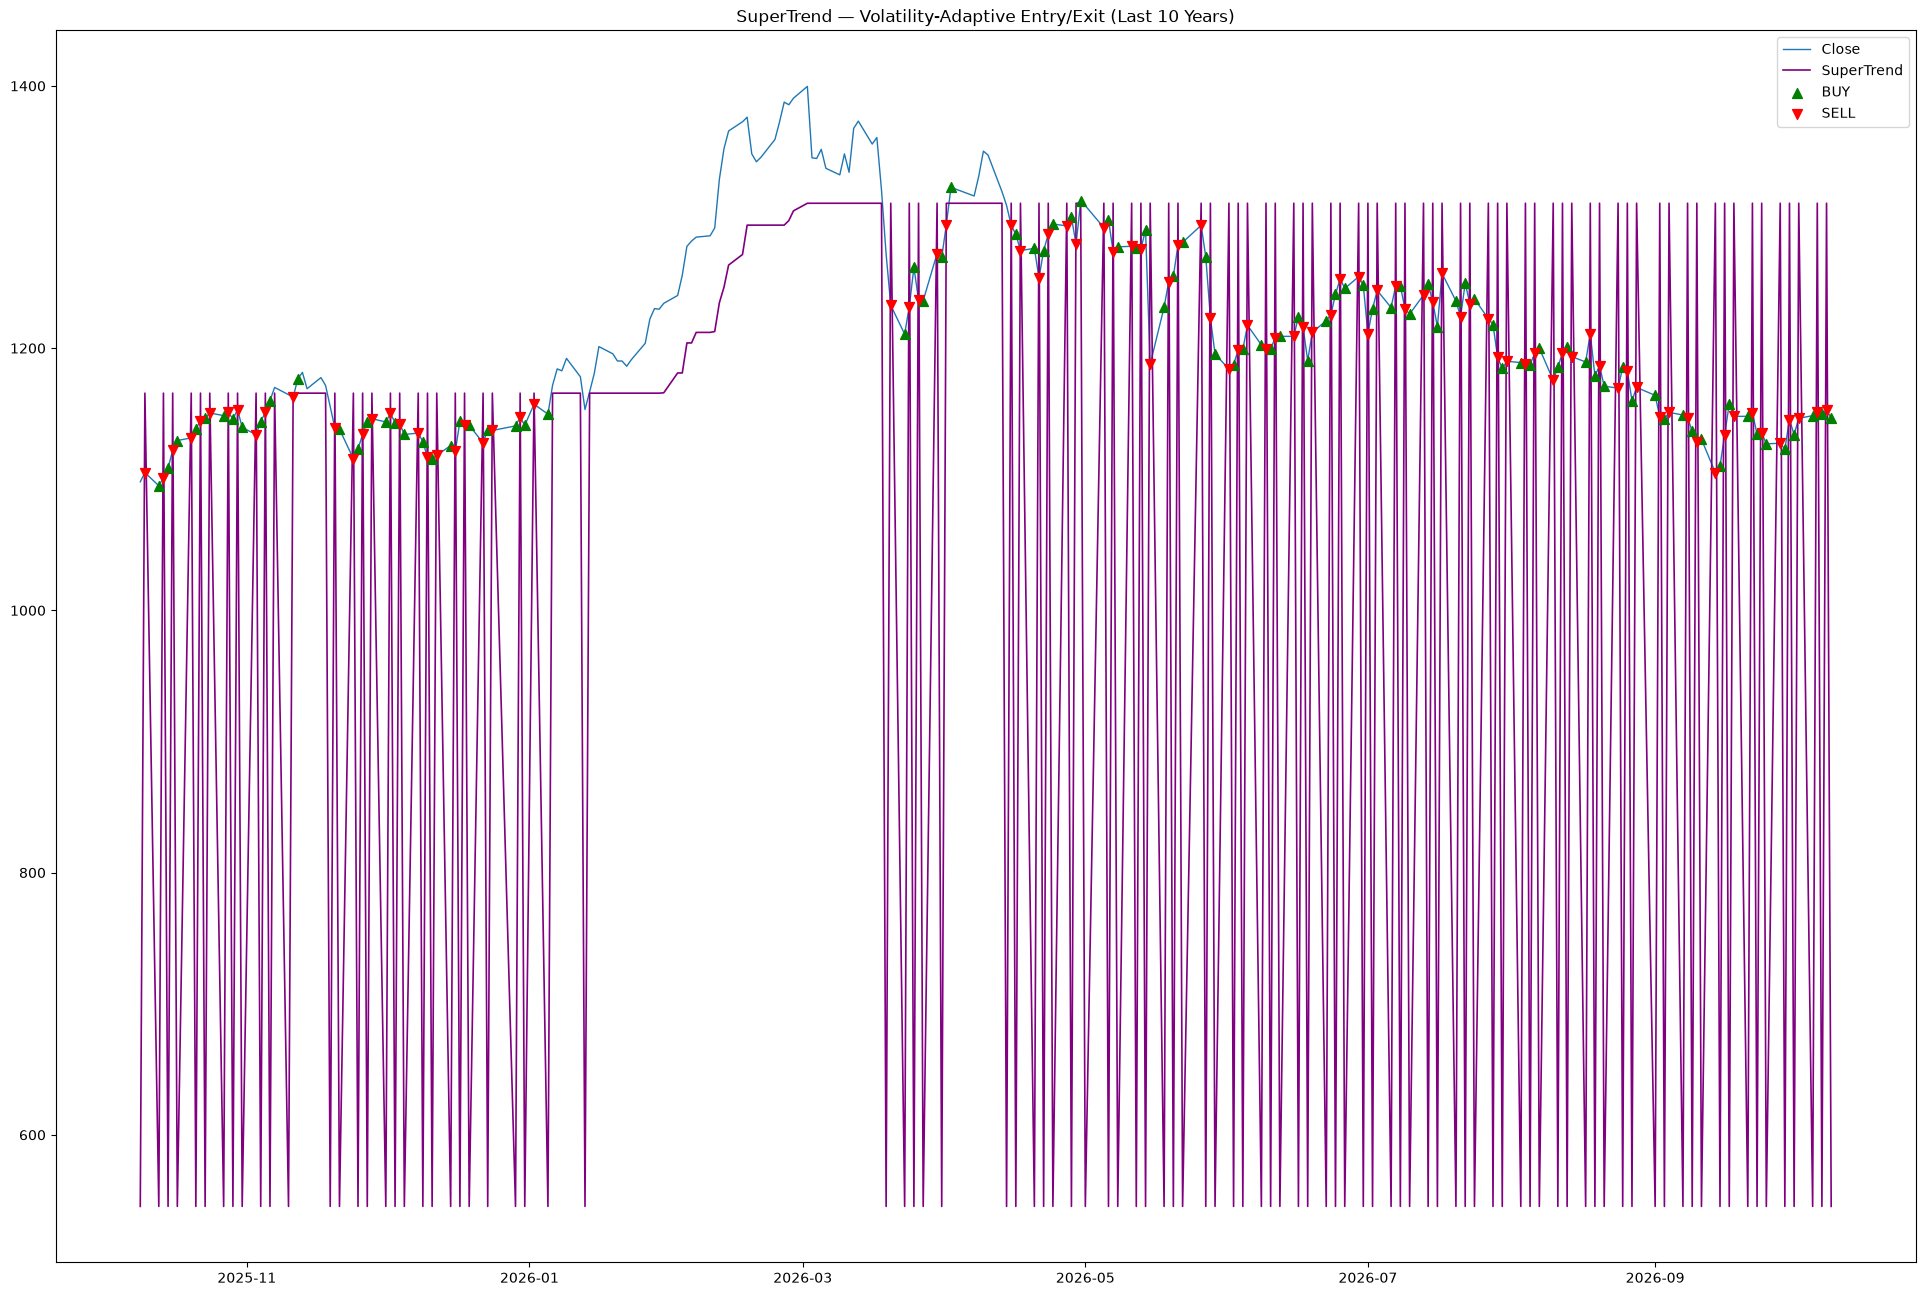

In [30]:
# === 6. SuperTrend ===
# --- FILTER TO LAST 10 YEARS ---
cutoff = df.index.max() - pd.DateOffset(months=12)
df_recent = df[df.index >= cutoff]

close = df_recent["Close"]
st = df_recent["ta_supertrend"]
st_dir = df_recent["ta_supertrend_direction"]

df_recent["price_above_st"] = close > st
df_recent["prev_above_st"] = df_recent["price_above_st"].shift(1)
df_recent["st_buy"] = (df_recent["price_above_st"] == True) & (df_recent["prev_above_st"] == False)
df_recent["st_sell"] = (df_recent["price_above_st"] == False) & (df_recent["prev_above_st"] == True)

print("\n=== SuperTrend Signals (Last 10 Years) ===")
print(f"Buy signals:  {df_recent['st_buy'].sum()}")
print(f"Sell signals: {df_recent['st_sell'].sum()}")

st_buy_idx = df_recent[df_recent["st_buy"]].index
st_buy_prices = close[st_buy_idx]
st_sell_idx = df_recent[df_recent["st_sell"]].index
st_sell_prices = close[st_sell_idx]

fig, ax = plt.subplots(figsize=(24, 16))
ax.plot(close.index, close, label="Close", linewidth=1)
ax.plot(close.index, st, label="SuperTrend", linewidth=1.2, color="purple")
ax.scatter(st_buy_idx, st_buy_prices, marker="^", color="green", s=50, zorder=5, label="BUY")
ax.scatter(st_sell_idx, st_sell_prices, marker="v", color="red", s=50, zorder=5, label="SELL")
ax.legend()
ax.set_title("SuperTrend — Volatility-Adaptive Entry/Exit (Last 10 Years)")
plt.show()

In [10]:
# === 7. Combined Trend Score ===
# --- FILTER TO LAST 10 YEARS ---
cutoff = df.index.max() - pd.DateOffset(years=10)
df_recent = df[df.index >= cutoff]

close = df_recent["Close"]
ema20 = df_recent["ta_ema20"]
ema50 = df_recent["ta_ema50"]
ema200 = df_recent["ta_ema200"]
st_dir = df_recent["ta_supertrend_direction"].fillna(-1)

df_recent["score_ema20"] = (close > ema20).astype(int) * 2 - 1
df_recent["score_ema50"] = (close > ema50).astype(int) * 2 - 1
df_recent["score_ema200"] = (close > ema200).astype(int) * 2 - 1
df_recent["score_cross"] = (ema50 > ema200).astype(int) * 2 - 1
df_recent["score_st"] = st_dir

df_recent["trend_score"] = df_recent["score_ema20"] + df_recent["score_ema50"] + df_recent["score_ema200"] + df_recent["score_cross"] + df_recent["score_st"]

def classify(score):
    if score >= 4: return "STRONG BUY"
    elif score >= 2: return "BUY"
    elif score == 0: return "NEUTRAL"
    elif score >= -2: return "SELL"
    else: return "STRONG SELL"

df_recent["trend_classification"] = df_recent["trend_score"].apply(classify)

print("\n=== Combined Trend Classification (Last 10 Years) ===")
print(df_recent["trend_classification"].value_counts())

print("\n=== Latest Assessment ===")
latest = df_recent.iloc[-1]
print(f"Date: {latest.name.strftime('%Y-%m-%d')}  Close: {latest['Close']:.2f}")
print(f"EMA20:  {'Bullish' if latest['Close'] > latest['ta_ema20'] else 'Bearish'}")
print(f"EMA50:  {'Bullish' if latest['Close'] > latest['ta_ema50'] else 'Bearish'}")
print(f"EMA200: {'Bullish' if latest['Close'] > latest['ta_ema200'] else 'Bearish'}")
print(f"Cross:  {'Bullish' if latest['ta_ema50'] > latest['ta_ema200'] else 'Bearish'}")
print(f"ST:     {'Bullish' if latest['ta_supertrend_direction'] == 1 else 'Bearish'}")
print(f"Score:  {latest['trend_classification']} ({int(latest['trend_score'])}/5)")


=== Combined Trend Classification ===
trend_classification
SELL           1647
STRONG SELL    1309
STRONG BUY     1101
BUY             998
Name: count, dtype: int64

=== Latest Assessment ===
Date: 2026-10-09  Close: 1147.00
EMA20:  Bullish
EMA50:  Bearish
EMA200: Bearish
Cross:  Bearish
ST:     Bearish
Score:  STRONG SELL (-3/5)


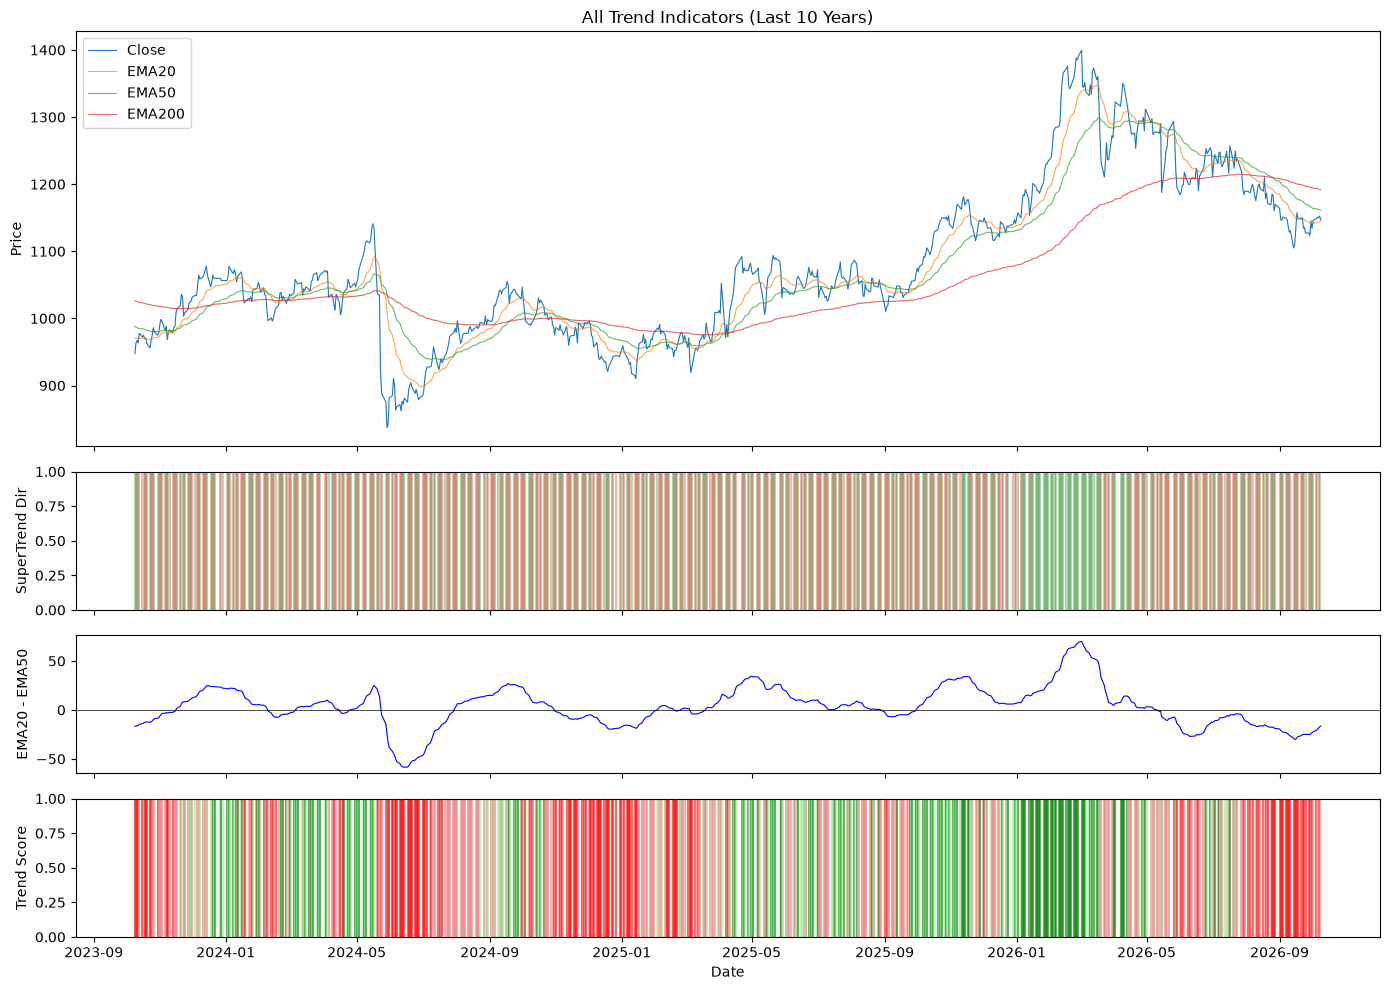

In [33]:
# === 8. Combined Timeline ===
# --- FILTER TO LAST 10 YEARS (self-contained) ---
cutoff8 = df.index.max() - pd.DateOffset(years=3)
df8 = df[df.index >= cutoff8]
close8 = df8["Close"]
ema20_8 = df8["ta_ema20"]
ema50_8 = df8["ta_ema50"]
ema200_8 = df8["ta_ema200"]
st_dir_8 = df8["ta_supertrend_direction"].fillna(-1)

df8["score_ema20"] = (close8 > ema20_8).astype(int) * 2 - 1
df8["score_ema50"] = (close8 > ema50_8).astype(int) * 2 - 1
df8["score_ema200"] = (close8 > ema200_8).astype(int) * 2 - 1
df8["score_cross"] = (ema50_8 > ema200_8).astype(int) * 2 - 1
df8["score_st"] = st_dir_8
df8["trend_score"] = df8["score_ema20"] + df8["score_ema50"] + df8["score_ema200"] + df8["score_cross"] + df8["score_st"]
df8["trend_classification"] = df8["trend_score"].apply(classify)

fig, axes = plt.subplots(4, 1, figsize=(14, 10), sharex=True, gridspec_kw={"height_ratios": [3, 1, 1, 1]})

axes[0].plot(close8.index, close8, label="Close", linewidth=0.8)
axes[0].plot(close8.index, ema20_8, label="EMA20", linewidth=0.8, alpha=0.7)
axes[0].plot(close8.index, ema50_8, label="EMA50", linewidth=0.8, alpha=0.7)
axes[0].plot(close8.index, ema200_8, label="EMA200", linewidth=0.8, alpha=0.7)
axes[0].set_ylabel("Price")
axes[0].legend(loc="upper left")
axes[0].set_title("All Trend Indicators (Last 10 Years)")

st_colors = st_dir_8.map({1: "green", -1: "red"})
for i in range(len(df8) - 1):
    axes[1].axvline(df8.index[i], color=st_colors.iloc[i], alpha=0.3)
axes[1].set_ylabel("SuperTrend Dir")

df8["ema_diff"] = ema20_8 - ema50_8
axes[2].plot(df8.index, df8["ema_diff"], color="blue", linewidth=0.8)
axes[2].axhline(0, color="black", linestyle="-", linewidth=0.5)
axes[2].set_ylabel("EMA20 - EMA50")

colors_map = {"STRONG BUY": "green", "BUY": "lightgreen", "NEUTRAL": "gray", "SELL": "lightcoral", "STRONG SELL": "red"}
class_colors = df8["trend_classification"].map(colors_map)
for i in range(len(df8) - 1):
    axes[3].axvline(df8.index[i], color=class_colors.iloc[i], alpha=0.6)
axes[3].set_ylabel("Trend Score")
axes[3].set_xlabel("Date")

plt.tight_layout()
plt.show()